# Install and import required python pacakges

In [ ]:
!pip install -q shap scikit-optimize
! pip install -q optuna
! pip install -q tensorflow
!pip install -q keras-tuner


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 1.6 MB/s eta 0:00:00


In [ ]:
#Install basic python pcakges
import math
import numpy as np
import pandas as pd

import os
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.metrics import mean_squared_log_error
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from time import time


# Data exploration

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/MTL/Multi_output_regression/Mean_Mse/Data_parameter_based.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df


,MAT_Dendrimer,MAT_Gold,MAT_Hybrid,MAT_Hydrogel,MAT_Iron Oxide,MAT_Liposome,MAT_Other IM,MAT_Other OM,MAT_Polymeric,MAT_Silica,...,Shape_Spherical,Size,Zeta Potential,TS,DE_heart,DE_liver,DE_spleen,DE_lung,DE_kidney,DE_tumor
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,2.060698,-18.00,0,-1.311603,3.273766,0.998486,-1.223573,-0.157671,0.679016
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.623249,-5.00,0,-1.147855,2.446097,1.477936,-0.867215,0.151123,1.037300
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.835056,-9.30,0,-1.493993,3.723862,0.658348,-0.266770,0.660268,-0.309404
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,2.060698,-12.50,1,-1.638148,0.696082,0.895844,0.230319,-1.483365,-2.658497
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.382017,-21.30,0,-0.123644,2.795489,-0.354286,-1.530822,0.308299,0.571684
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,1.686636,-0.11,1,-2.767623,1.618834,-2.693418,-1.353566,-0.825813,-0.928559
294,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,1.843507,-12.90,0,-0.736751,3.190462,-0.742580,0.700832,0.924272,0.517519
295,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,2.203577,-10.98,0,-3.002974,2.240069,-0.416482,-1.159694,0.011363,1.407737
296,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,2.208979,-10.76,0,-2.837476,2.043847,-0.571513,-1.314720,-0.203231,2.400653


In [ ]:
target_cols = ['DE_tumor','DE_heart','DE_liver','DE_spleen','DE_lung','DE_kidney']
Y_re = df[target_cols]
X_re = df.drop(columns=target_cols)


# Deep nerual network model

In [ ]:
# import basic packages
import numpy as np
import pandas as pd
import keras_tuner as kt
import tensorflow as tf
# import scikeras
from tensorflow import keras
# import keras related packages
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
import kerastuner as kt
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from keras import regularizers
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from keras.models import load_model
from keras.callbacks import EarlyStopping
# from tensorflow.keras.wrappers.scikit_learn import KerasRegressor
from keras_tuner import BayesianOptimization
from keras_tuner import Hyperband
from tensorflow import keras
from tensorflow.keras import layers
from keras_tuner import Objective
from tensorflow.keras.optimizers import Adam
from tensorflow.python.ops import math_ops
from sklearn.metrics import mean_squared_error as mse


/tmp/ipykernel_4912/269820995.py:12: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  import kerastuner as kt


In [ ]:
X = X_re.to_numpy()
y = Y_re.to_numpy()
# summarize shape
print(X.shape, y.shape)


(298, 28) (298, 6)


In [ ]:
from sklearn.model_selection import train_test_split
X_temp, X_test, y_temp, y_test = train_test_split(X, y,test_size = 0.2, random_state=3407)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,test_size = 0.125, random_state=3407)
print(X_train.shape, X_val.shape, X_test.shape)


(208, 28) (30, 28) (60, 28)


In [ ]:
Y_re.head()


,DE_tumor,DE_heart,DE_liver,DE_spleen,DE_lung,DE_kidney
0,0.679016,-1.311603,3.273766,0.998486,-1.223573,-0.157671
1,1.037300,-1.147855,2.446097,1.477936,-0.867215,0.151123
2,-0.309404,-1.493993,3.723862,0.658348,-0.266770,0.660268
3,-2.658497,-1.638148,0.696082,0.895844,0.230319,-1.483365
4,0.571684,-0.123644,2.795489,-0.354286,-1.530822,0.308299


# Tuning Model

In [ ]:
TASKS = [
    ("tumor",  "DE_tumor_out_layer"),
    ("heart",  "DE_heart_out_layer"),
    ("liver",  "DE_liver_out_layer"),
    ("spleen", "DE_spleen_out_layer"),
    ("lung",   "DE_lung_out_layer"),
    ("kidney", "DE_kidney_out_layer"),
]

out_names = [out for _, out in TASKS]

def make_y_dict(y):
    return {name: y[:, i] for i, name in enumerate(out_names)}

y_train_dict = make_y_dict(y_train)
y_val_dict   = make_y_dict(y_val)
y_temp_dict  = make_y_dict(y_temp)


In [ ]:
NUM_TASKS = len(TASKS)
LOSS_WEIGHTS = {out_name: 1.0 / NUM_TASKS for _, out_name in TASKS}

def mse_loss(y_true, y_pred):
    return tf.reduce_mean(tf.square(y_true - y_pred))


In [ ]:
# Optuna model definition (replace Keras Tuner HyperModel)
import optuna

def MTL_DNN(params, input_dim: int):
    out_names = [out for _, out in TASKS]

    inputs = Input(shape=(int(input_dim),), name="input")
    x = inputs

    n_shared = int(params["n_shared_layers"])
    for i in range(1, n_shared + 1):
        x = Dense(units=int(params[f"shared_units_{i}"]),kernel_regularizer=l2(float(params[f"shared_l2_{i}"])),
            use_bias=False,name=f"shared_dense_{i}",)(x)
        x = BatchNormalization(name=f"shared_bn_{i}")(x)
        x = Activation("relu", name=f"shared_act_{i}")(x)
        x = Dropout(float(params[f"shared_dropout_{i}"]), name=f"shared_dropout_{i}")(x)

    outputs = []
    metrics = {}
    n_specific = int(params["n_specific_layers"])

    for idx, (task_key, out_name) in enumerate(TASKS, start=1):
        h = x
        for j in range(1, n_specific + 1):
            h = Dense(
                units=int(params[f"specific_units_{idx}_{j}"]),
                kernel_regularizer=l2(float(params[f"specific_l2_{idx}_{j}"])),
                use_bias=False,
                name=f"{task_key}_dense_{j}",
            )(h)
            h = Activation("relu", name=f"{task_key}_act_{j}")(h)
            h = Dropout(float(params[f"specific_dropout_{idx}_{j}"]), name=f"{task_key}_dropout_{j}")(h)

        outputs.append(Dense(1, name=out_name)(h))
        metrics[out_name] = [tf.keras.metrics.MeanSquaredError(name="mse")]

    model = Model(inputs, outputs, name="MTL_DNN_mean_mse")
    losses = {out_name: mse_loss for _, out_name in TASKS}

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=float(params["learning_rate"])),
        loss=losses,
        loss_weights=LOSS_WEIGHTS,
        metrics=metrics,
    )
    return model


In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, Dropout, Activation, BatchNormalization
from tensorflow.keras.regularizers import l2
import optuna

def objective(trial):
    params = {}

    params["n_shared_layers"] = trial.suggest_categorical("n_shared_layers", [1, 2])
    for i in [1,2]:
        params[f"shared_units_{i}"] = trial.suggest_int(f"shared_units_{i}", 32, 256, step=16)
        params[f"shared_l2_{i}"] = trial.suggest_float(f"shared_l2_{i}", 1e-5, 1e-2, log=True)
        params[f"shared_dropout_{i}"] = trial.suggest_categorical(f"shared_dropout_{i}", [0.2, 0.4])

    params["n_specific_layers"] = trial.suggest_categorical("n_specific_layers", [1, 2])
    for idx in range(1, 7):
        for j in [1, 2]:
            params[f"specific_units_{idx}_{j}"] = trial.suggest_int(f"specific_units_{idx}_{j}", 8, 32, step=8)
            params[f"specific_l2_{idx}_{j}"] = trial.suggest_float(f"specific_l2_{idx}_{j}", 1e-5, 1e-2, log=True)
            params[f"specific_dropout_{idx}_{j}"] = trial.suggest_categorical(f"specific_dropout_{idx}_{j}", [0.1, 0.2])

    params["learning_rate"] = trial.suggest_categorical("learning_rate", [1e-3, 3e-4, 1e-4, 3e-5])

    tf.keras.backend.clear_session()

    model = MTL_DNN(
        params=params,input_dim=X_train.shape[1])

    history = model.fit(
        X_train, y_train_dict,
        validation_data=(X_val, y_val_dict),
        epochs=100,
        batch_size=32,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=8,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    return float(np.min(history.history["val_loss"]))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=20)


[I 2026-06-12 13:50:32,863] A new study created in memory with name: no-name-7ffb79bc-a803-47ce-bceb-8d29bd6fa22f
[I 2026-06-12 13:50:57,555] Trial 0 finished with value: 3.5146307945251465 and parameters: {'n_shared_layers': 2, 'shared_units_1': 192, 'shared_l2_1': 0.0006251373574521745, 'shared_dropout_1': 0.2, 'shared_units_2': 32, 'shared_l2_2': 0.003967605077052989, 'shared_dropout_2': 0.4, 'n_specific_layers': 2, 'specific_units_1_1': 32, 'specific_l2_1_1': 4.335281794951564e-05, 'specific_dropout_1_1': 0.2, 'specific_units_1_2': 16, 'specific_l2_1_2': 0.00037520558551242813, 'specific_dropout_1_2': 0.1, 'specific_units_2_1': 24, 'specific_l2_2_1': 2.621087878265438e-05, 'specific_dropout_2_1': 0.2, 'specific_units_2_2': 16, 'specific_l2_2_2': 0.0022673986523780395, 'specific_dropout_2_2': 0.2, 'specific_units_3_1': 24, 'specific_l2_3_1': 1.3783237455007187e-05, 'specific_dropout_3_1': 0.1, 'specific_units_3_2': 8, 'specific_l2_3_2': 0.007025166339242158, 'specific_dropout_3_2': 

In [ ]:
best_params = study.best_params
print("Best params:", best_params)
print("Best val_loss:", study.best_value)


Best params: {'n_shared_layers': 1, 'shared_units_1': 128, 'shared_l2_1': 0.00012638229388046486, 'shared_dropout_1': 0.4, 'shared_units_2': 176, 'shared_l2_2': 0.0015908408497908515, 'shared_dropout_2': 0.2, 'n_specific_layers': 1, 'specific_units_1_1': 16, 'specific_l2_1_1': 1.033285556962607e-05, 'specific_dropout_1_1': 0.2, 'specific_units_1_2': 8, 'specific_l2_1_2': 5.956273871427392e-05, 'specific_dropout_1_2': 0.2, 'specific_units_2_1': 24, 'specific_l2_2_1': 4.447346062127476e-05, 'specific_dropout_2_1': 0.1, 'specific_units_2_2': 16, 'specific_l2_2_2': 0.0014439751146224267, 'specific_dropout_2_2': 0.1, 'specific_units_3_1': 8, 'specific_l2_3_1': 6.016171964933736e-05, 'specific_dropout_3_1': 0.2, 'specific_units_3_2': 8, 'specific_l2_3_2': 0.005097156857803537, 'specific_dropout_3_2': 0.1, 'specific_units_4_1': 24, 'specific_l2_4_1': 1.1588527855206525e-05, 'specific_dropout_4_1': 0.1, 'specific_units_4_2': 16, 'specific_l2_4_2': 0.00010029291168248427, 'specific_dropout_4_2'

In [ ]:
best_model = MTL_DNN(
    params=best_params,
    input_dim=X_train.shape[1],
)

history = best_model.fit(
    X_train, y_train_dict,
    validation_data=(X_val, y_val_dict),
    epochs=1024,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=32,
            restore_best_weights=True,
        )
    ],
    verbose=0,
)

In [ ]:
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_model.fit(
    X_temp, y_temp_dict,
    epochs=best_epoch,
    batch_size=32,
    verbose=0)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

OUT_NAMES = best_model.output_names
TASK_NAMES = ["tumor", "heart", "liver", "spleen", "lung", "kidney"]

def preds_to_dict(preds, out_names):
    return {
        out_names[i]: np.asarray(preds[i]).reshape(-1)
        for i in range(len(out_names))
    }

temp_preds = preds_to_dict(best_model.predict(X_temp, verbose=0), OUT_NAMES)
test_preds = preds_to_dict(best_model.predict(X_test, verbose=0), OUT_NAMES)


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

def eval_multitask(y_true_mat, preds_dict, split_name):
    print(f"\n===== {split_name} =====")
    rmses = []
    r2s = []

    for i, (task, out_name) in enumerate(zip(TASK_NAMES, OUT_NAMES)):
        y_true = y_true_mat[:, i].reshape(-1)
        y_pred = preds_dict[out_name].reshape(-1)

        r2 = r2_score(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))

        r2s.append(r2)
        rmses.append(rmse)

        print(f"{task:>7s} | R2 = {r2: .3f} | RMSE = {rmse: .3f}")

# ---- run evaluation ----
eval_multitask(y_temp, temp_preds, "Train+Val")
eval_multitask(y_test, test_preds, "Test")





===== Train+Val =====
  tumor | R2 =  0.661 | RMSE =  0.882
  heart | R2 =  0.616 | RMSE =  1.024
  liver | R2 =  0.619 | RMSE =  0.952
 spleen | R2 =  0.710 | RMSE =  1.008
   lung | R2 =  0.564 | RMSE =  1.043
 kidney | R2 =  0.497 | RMSE =  1.218

===== Test =====
  tumor | R2 =  0.005 | RMSE =  1.782
  heart | R2 =  0.161 | RMSE =  1.534
  liver | R2 =  0.084 | RMSE =  1.575
 spleen | R2 =  0.044 | RMSE =  1.673
   lung | R2 =  0.127 | RMSE =  1.378
 kidney | R2 =  0.106 | RMSE =  1.363


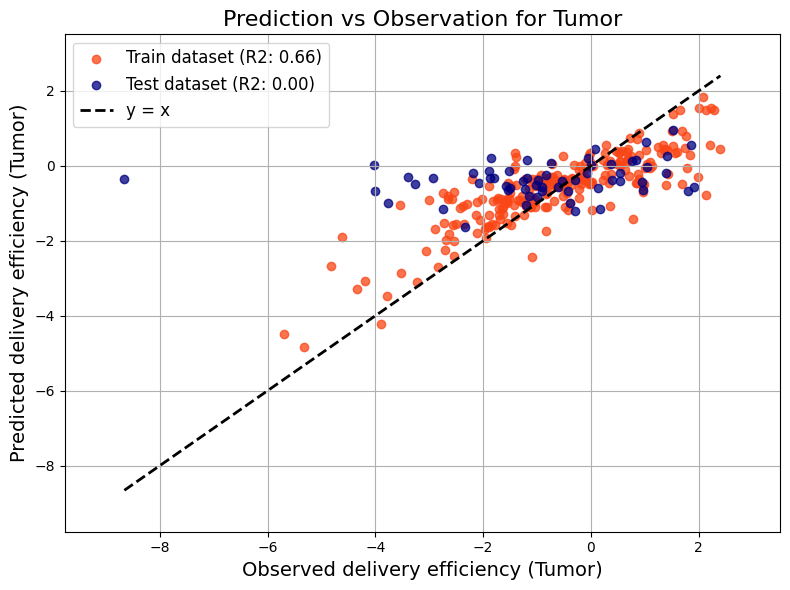

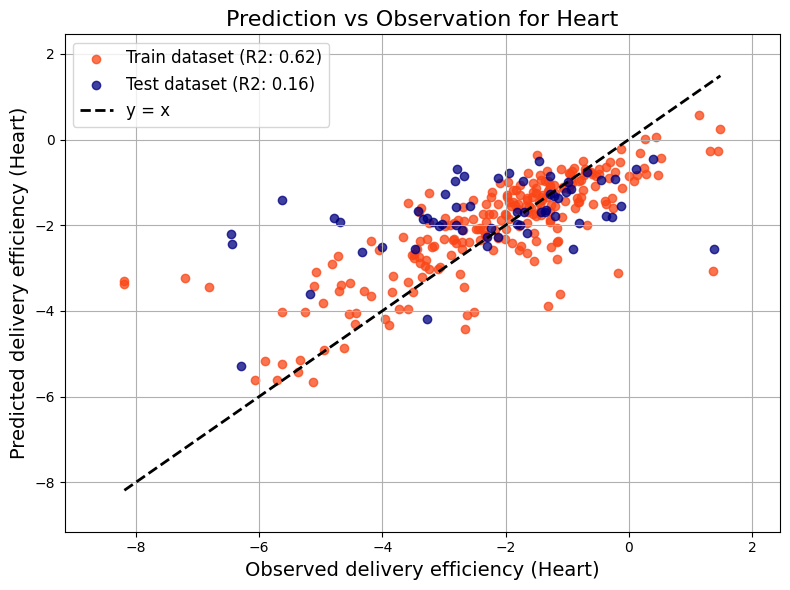

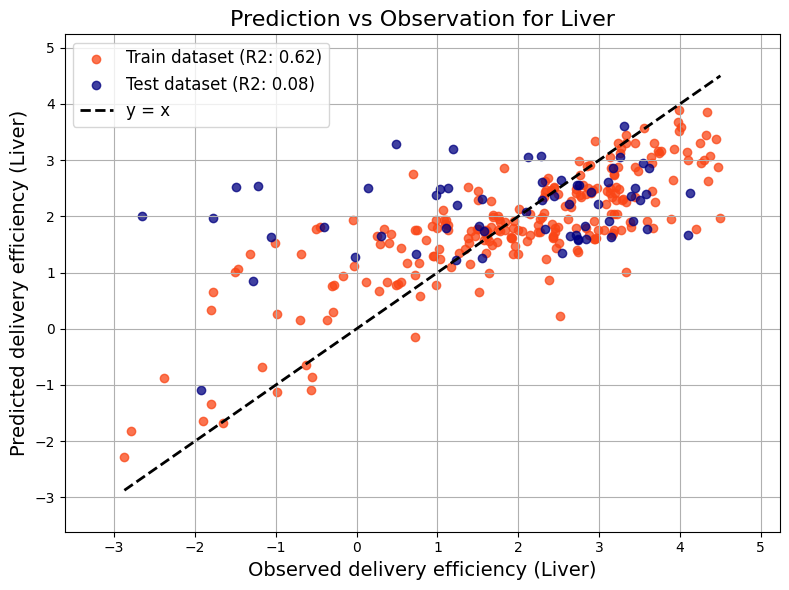

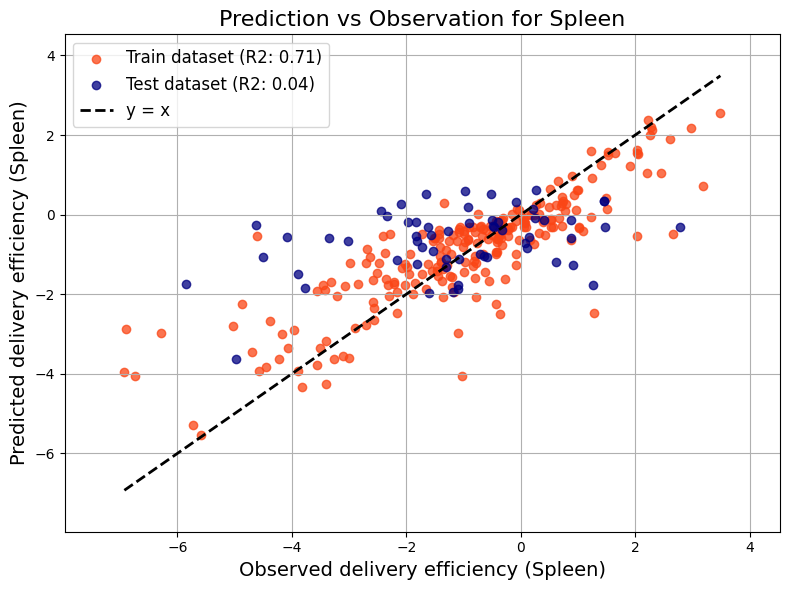

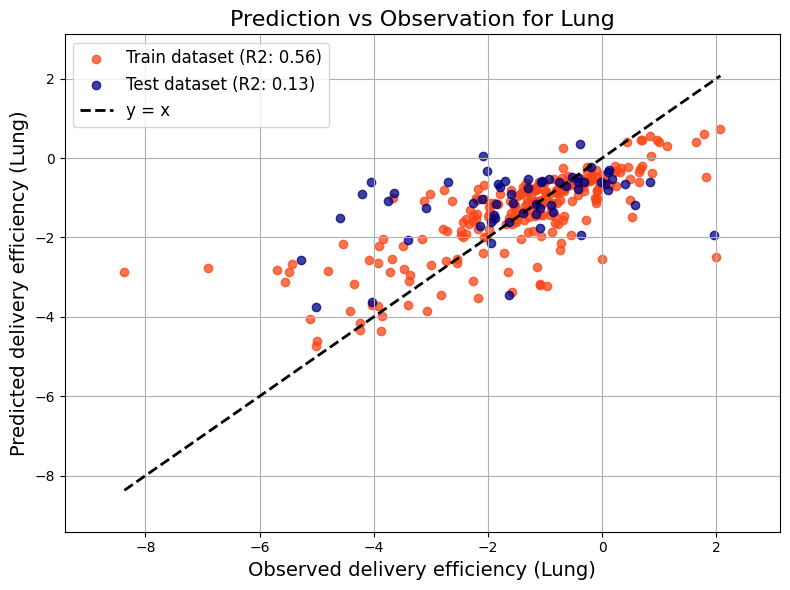

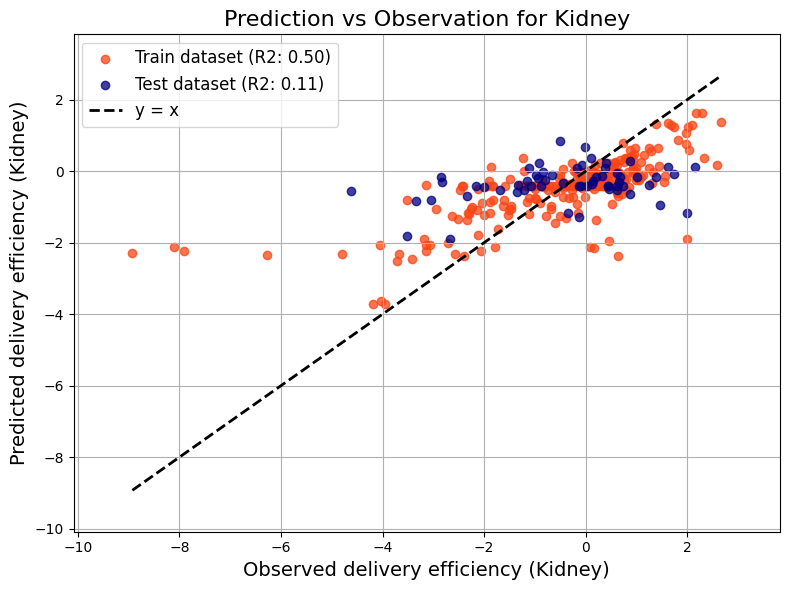

In [ ]:
def plot_regression_for_task(task_index, task_name):
    out_name = OUT_NAMES[task_index]

    # Calculate R2 for Train+Val
    y_true_temp = y_temp[:, task_index].reshape(-1)
    y_pred_temp = temp_preds[out_name].reshape(-1)
    r2_temp = r2_score(y_true_temp, y_pred_temp)

    # Calculate R2 for Test
    y_true_test = y_test[:, task_index].reshape(-1)
    y_pred_test = test_preds[out_name].reshape(-1)
    r2_test = r2_score(y_true_test, y_pred_test)

    plt.figure(figsize=(8, 6))

    # scatter: train
    plt.scatter(
        y_temp[:, task_index],
        temp_preds[out_name],
        c="#FA4616",
        alpha=0.75,
        label=f"Train dataset (R2: {r2_temp:.2f})"
    )

    # scatter: test
    plt.scatter(
        y_test[:, task_index],
        test_preds[out_name],
        c="#000080",
        alpha=0.75,
        label=f"Test dataset (R2: {r2_test:.2f})"
    )

    # labels & title
    plt.xlabel(f"Observed delivery efficiency ({task_name.capitalize()})", fontsize=14)
    plt.ylabel(f"Predicted delivery efficiency ({task_name.capitalize()})", fontsize=14)
    plt.title(f"Prediction vs Observation for {task_name.capitalize()}", fontsize=16)

    # axis limits
    all_y = np.concatenate([y_temp[:, task_index], y_test[:, task_index]])
    all_pred = np.concatenate([temp_preds[out_name], test_preds[out_name]])

    min_val = min(all_y.min(), all_pred.min())
    max_val = max(all_y.max(), all_pred.max())
    padding = 0.1 * (max_val - min_val)

    plt.xlim(min_val - padding, max_val + padding)
    plt.ylim(min_val - padding, max_val + padding)

    # y = x line
    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--",
        linewidth=2,
        color="black",
        label="y = x"
    )

    plt.legend(loc="upper left", fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for i, task_name in enumerate(TASK_NAMES):
    plot_regression_for_task(i, task_name)



In [ ]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error
import tensorflow as tf

# Define the number of folds for cross-validation
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize dictionaries to store results for each task and each fold
all_fold_r2s = {task_name: [] for task_name, _ in TASKS}
all_fold_rmses = {task_name: [] for task_name, _ in TASKS}

print(f"Starting {n_splits}-Fold Cross-Validation...")

# Loop through each fold
fold_idx = 1
for train_index, val_index in kf.split(X_temp):
    print(f"\n--- Cross-validation Fold {fold_idx}/{n_splits} ---")

    X_train_fold, X_val_fold = X_temp[train_index], X_temp[val_index]
    y_train_fold, y_val_fold = y_temp[train_index], y_temp[val_index]

    # Convert numpy arrays to dictionaries for multi-task model input
    y_train_fold_dict = make_y_dict(y_train_fold)
    y_val_fold_dict = make_y_dict(y_val_fold)

    # Clear TensorFlow session to avoid graph pollution from previous runs
    tf.keras.backend.clear_session()

    # Create and compile a new model for each fold using the best_params found earlier
    cv_model = MTL_DNN(
        params=best_params,
        input_dim=X_train_fold.shape[1],
    )

    # Train the model with early stopping on the current fold's data
    history_cv = cv_model.fit(
        X_train_fold, y_train_fold_dict,
        validation_data=(X_val_fold, y_val_fold_dict),
        epochs=1024, # Use a high number, early stopping will stop training when validation loss stops improving
        batch_size=32,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=32, # Patience parameter for early stopping
                restore_best_weights=True,
            )
        ],
        verbose=0, # Suppress verbose output during training
    )

    # Evaluate the model on the validation set of the current fold
    fold_val_preds = preds_to_dict(cv_model.predict(X_val_fold, verbose=0), OUT_NAMES)

    # Calculate and store R2 and RMSE metrics for each task in the current fold
    for i, (task_key, out_name) in enumerate(TASKS):
        y_true_task = y_val_fold[:, i].reshape(-1)
        y_pred_task = fold_val_preds[out_name].reshape(-1)

        r2 = r2_score(y_true_task, y_pred_task)
        rmse = np.sqrt(mean_squared_error(y_true_task, y_pred_task))

        all_fold_r2s[task_key].append(r2)
        all_fold_rmses[task_key].append(rmse)
        print(f"  {task_key:>7s} | R2 = {r2: .3f} | RMSE = {rmse: .3f}")

    fold_idx += 1

print("\n=======================================================")
print("===== Cross-validation Results (Average across folds) ====")
print("=======================================================")
for task_key, _ in TASKS:
    avg_r2 = np.mean(all_fold_r2s[task_key])
    std_r2 = np.std(all_fold_r2s[task_key])
    avg_rmse = np.mean(all_fold_rmses[task_key])
    std_rmse = np.std(all_fold_rmses[task_key])

    print(f"{task_key:>7s} | Avg R2 = {avg_r2: .3f} +/- {std_r2: .3f} | Avg RMSE = {avg_rmse: .3f} +/- {std_rmse: .3f}")



Starting 5-Fold Cross-Validation...

--- Cross-validation Fold 1/5 ---
    tumor | R2 =  0.276 | RMSE =  1.399
    heart | R2 =  0.252 | RMSE =  1.619
    liver | R2 =  0.330 | RMSE =  1.298
   spleen | R2 =  0.371 | RMSE =  1.742
     lung | R2 =  0.231 | RMSE =  1.679
   kidney | R2 =  0.234 | RMSE =  1.837

--- Cross-validation Fold 2/5 ---
    tumor | R2 =  0.220 | RMSE =  1.218
    heart | R2 = -0.013 | RMSE =  1.631
    liver | R2 =  0.334 | RMSE =  1.249
   spleen | R2 =  0.491 | RMSE =  1.336
     lung | R2 =  0.063 | RMSE =  1.378
   kidney | R2 =  0.144 | RMSE =  1.664

--- Cross-validation Fold 3/5 ---
    tumor | R2 =  0.091 | RMSE =  1.402
    heart | R2 = -0.061 | RMSE =  1.695
    liver | R2 = -0.013 | RMSE =  1.556
   spleen | R2 =  0.217 | RMSE =  1.544
     lung | R2 =  0.017 | RMSE =  1.459
   kidney | R2 = -0.039 | RMSE =  1.408

--- Cross-validation Fold 4/5 ---
    tumor | R2 = -0.090 | RMSE =  1.387
    heart | R2 = -0.175 | RMSE =  1.404
    liver | R2 = -0.256 